In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

Setup, nạp evaluate.py & kiểm tra dữ liệu

In [1]:
# ── Cell 1: Setup & tạo file evaluate.py của Hà ───────────────────────────
import os, glob, json, time, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

# Ghi file evaluate.py của Hà vào thư mục làm việc để import trực tiếp
with open('evaluate.py', 'w', encoding='utf-8') as f:
    f.write('''import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_model(y_true, y_pred, class_names, model_name="Model", save_dir="results/"):
    acc = accuracy_score(y_true, y_pred)
    macro_p = precision_score(y_true, y_pred, average='macro', zero_division=0)
    macro_r = recall_score(y_true, y_pred, average='macro', zero_division=0)
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    
    print(f"=== KẾT QUẢ ĐÁNH GIÁ: {model_name} ===")
    print(f"Accuracy        : {acc:.4f}")
    print(f"Macro Precision : {macro_p:.4f}")
    print(f"Macro Recall    : {macro_r:.4f}")
    print(f"Macro F1-Score  : {macro_f1:.4f}\\n")
    
    print("--- Báo cáo phân loại chi tiết ---")
    print(classification_report(y_true, y_pred, target_names=class_names, zero_division=0))
    
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(10, 8))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'Confusion Matrix - {model_name}')
    plt.ylabel('Thực tế (True)')
    plt.xlabel('Dự đoán (Predicted)')
    plt.tight_layout()
    
    os.makedirs(save_dir, exist_ok=True)
    cm_path = os.path.join(save_dir, f'confusion_matrix_{model_name.replace(" ", "_")}.png')
    plt.savefig(cm_path, dpi=300)
    print(f"Đã lưu biểu đồ Confusion Matrix tại: {cm_path}")
    plt.show()
    plt.close()
    
    return {
        "accuracy": acc,
        "macro_precision": macro_p,
        "macro_recall": macro_r,
        "macro_f1": macro_f1
    }
''')

from evaluate import evaluate_model

# Cố định Seed = 42
SEED = 42
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
CLASS_NAMES = ['Casual', 'Daily', 'Ethnic', 'Festive', 'Party', 'Traditional', 'Western']
NUM_CLASSES = len(CLASS_NAMES)
print(f"✅ Device: {DEVICE} | evaluate.py ready!")

✅ Device: cuda | evaluate.py ready!


Load Features .pt + Tabular Features + Tính class_weights

In [2]:
# ── Cell 2: Load clean_v0.csv & Features (.pt) ────────────────────────────
CSV_PATH = glob.glob('/kaggle/input/**/clean_v0*.csv', recursive=True)[0]
df = pd.read_csv(CSV_PATH)

def find_pt(name):
    cands = glob.glob(f'/kaggle/input/**/{name}', recursive=True) + glob.glob(f'/kaggle/working/**/{name}', recursive=True)
    assert len(cands) > 0, f"Không tìm thấy {name}! Hãy Add Input dataset myntra-extracted-features"
    return cands[0]

# Tiền xử lý Tabular (7 cột từ clean_v0 của Hà -> chuẩn hóa)
TAB_CAT_COLS = ['colour', 'brand', 'fabric', 'pattern', 'wash_care', 'sustainable']

class TabularPreprocessor:
    def fit(self, df_tr):
        # 1. Price (log + min-max)
        p = np.log1p(df_tr['price'].astype(float))
        self.pmin, self.pmax = float(p.min()), float(p.max())
        # 2. Rating
        self.rmean = float(df_tr['avg_rating'].astype(float).mean())
        # 3. Categorical columns -> frequency/index encoding normalized [0, 1]
        self.cat_maps = {}
        for c in TAB_CAT_COLS:
            vals = sorted(df_tr[c].fillna('Unknown').astype(str).unique())
            self.cat_maps[c] = ({v: i + 1 for i, v in enumerate(vals)}, max(len(vals), 1))
        self.input_dim = 3 + len(TAB_CAT_COLS)  # price, avg_rating, has_rating + 6 cột cat = 9 chiều
        return self

    def transform(self, df_sub):
        p = np.log1p(df_sub['price'].astype(float))
        p_norm = np.clip((p - self.pmin) / (self.pmax - self.pmin + 1e-9), 0, 1).values
        
        r = df_sub['avg_rating'].fillna(self.rmean).astype(float)
        r_norm = np.clip((r - 1.0) / 4.0, 0, 1).values
        
        has_r = (df_sub['ratingCount'].fillna(0).astype(float) > 0).astype(float).values
        
        cols = [p_norm, r_norm, has_r]
        for c in TAB_CAT_COLS:
            mp, n_val = self.cat_maps[c]
            encoded = df_sub[c].fillna('Unknown').astype(str).map(lambda x: mp.get(x, 0) / n_val).values
            cols.append(encoded)
        return torch.tensor(np.stack(cols, axis=1), dtype=torch.float32)

df_train = df[df['split'] == 'train'].reset_index(drop=True)
tab_prep = TabularPreprocessor().fit(df_train)
TABULAR_DIM = tab_prep.input_dim

# Load toàn bộ 3 split
data_splits = {}
for s in ['train', 'val', 'test']:
    df_s = df[df['split'] == s].reset_index(drop=True)
    img_pt = torch.load(find_pt(f'image_feats_{s}.pt'))
    txt_pt = torch.load(find_pt(f'text_feats_{s}.pt'))
    
    # Đảm bảo khớp ID tuyệt đối
    assert (img_pt['ids'] == torch.tensor(df_s['id'].values)).all(), f"Lệch ID ở {s}!"
    assert (txt_pt['ids'] == torch.tensor(df_s['id'].values)).all(), f"Lệch ID ở {s}!"
    
    data_splits[s] = {
        'img': img_pt['feats'].float(),            # (N, 2048)
        'txt': txt_pt['feats'].float(),            # (N, 768)
        'tab': tab_prep.transform(df_s),           # (N, 9)
        'y'  : torch.tensor(df_s['label_idx'].values, dtype=torch.long)
    }
    print(f"✅ [{s:5s}] img={tuple(data_splits[s]['img'].shape)} | txt={tuple(data_splits[s]['txt'].shape)} | tab={tuple(data_splits[s]['tab'].shape)}")

# Tính Class Weights nhẹ (dùng căn bậc 2 để không làm lệch quá gắt lớp Casual)
counts = np.bincount(data_splits['train']['y'].numpy(), minlength=NUM_CLASSES)
raw_weights = counts.sum() / (NUM_CLASSES * np.clip(counts, 1, None))
smooth_weights = np.sqrt(raw_weights)  # Sqrt smoothing giúp tăng Macro-F1 mà không tụt Accuracy
class_weights = torch.tensor(smooth_weights, dtype=torch.float32).to(DEVICE)
print("\n⚖️ Class weights (smoothed):", np.round(smooth_weights, 3).tolist())

✅ [train] img=(8861, 2048) | txt=(8861, 768) | tab=(8861, 9)
✅ [val  ] img=(1899, 2048) | txt=(1899, 768) | tab=(1899, 9)
✅ [test ] img=(1899, 2048) | txt=(1899, 768) | tab=(1899, 9)

⚖️ Class weights (smoothed): [0.492, 1.051, 1.311, 1.264, 1.468, 2.41, 2.876]


T14: Định nghĩa các Models (Single-modal Heads + Multi-Modal Fusion)

In [4]:
# ── Cell 3: T14 - Kiến trúc Models (Single-modal & Multi-Modal Fusion) ────

class TextBaselineHead(nn.Module):
    """Model 3: Text-only Classifier trên vector 768-d của DistilBERT."""
    def __init__(self, in_dim=768, num_classes=NUM_CLASSES, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(in_dim),
            nn.Linear(in_dim, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes)
        )
    def forward(self, txt):
        return self.net(txt)


class TabularEncoder(nn.Module):
    """Nhánh 3: Tabular MLP (Input -> 32 -> 64) chuẩn theo Charter."""
    def __init__(self, in_dim=TABULAR_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 64),
            nn.ReLU()
        )
    def forward(self, tab):
        return self.net(tab)


class MultiModalFusionHead(nn.Module):
    """
    Model 4: Khối Hợp nhất (2048 + 768 + 64 = 2880 chiều)
    Linear(2880 -> 512) -> ReLU -> Dropout(0.3) -> Linear(512 -> 256) -> ReLU -> Linear(256 -> C)
    Có thêm LayerNorm từng nhánh trước khi concat (theo Debug Checklist mục 10.5).
    """
    def __init__(self, img_dim=2048, txt_dim=768, tab_in_dim=TABULAR_DIM,
                 num_classes=NUM_CLASSES, dropout=0.3):
        super().__init__()
        self.img_norm = nn.LayerNorm(img_dim)
        self.txt_norm = nn.LayerNorm(txt_dim)
        self.tab_encoder = TabularEncoder(tab_in_dim)
        self.tab_norm = nn.LayerNorm(64)
        
        fusion_dim = img_dim + txt_dim + 64  # 2880
        self.classifier = nn.Sequential(
            nn.Linear(fusion_dim, 512),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(dropout * 0.5),
            nn.Linear(256, num_classes)
        )

    def forward(self, img, txt, tab):
        f_img = self.img_norm(img)                # (B, 2048)
        f_txt = self.txt_norm(txt)                # (B, 768)
        f_tab = self.tab_norm(self.tab_encoder(tab))  # (B, 64)
        
        fused = torch.cat([f_img, f_txt, f_tab], dim=1)  # (B, 2880)
        return self.classifier(fused)

# Test nhanh Forward & Backward cho T14
dummy_model = MultiModalFusionHead().to(DEVICE)
b_img = data_splits['train']['img'][:8].to(DEVICE)
b_txt = data_splits['train']['txt'][:8].to(DEVICE)
b_tab = data_splits['train']['tab'][:8].to(DEVICE)
b_y   = data_splits['train']['y'][:8].to(DEVICE)

out = dummy_model(b_img, b_txt, b_tab)
loss = nn.CrossEntropyLoss()(out, b_y)
loss.backward()
print(f"✅ T14 Check: Output shape = {tuple(out.shape)} (kỳ vọng: (8, 7)) | Backward loss = {loss.item():.4f} OK!")

✅ T14 Check: Output shape = (8, 7) (kỳ vọng: (8, 7)) | Backward loss = 1.9690 OK!


T15: Training Loop chuẩn (CrossEntropyLoss, AdamW, Early Stopping)

In [5]:
# ── Cell 4: T15 - Training Loop dùng chung ────────────────────────────────
from sklearn.metrics import f1_score, accuracy_score

def train_model(model, mode='text', lr=1e-3, weight_decay=1e-2,
                batch_size=128, epochs=30, patience=6, use_class_weights=True,
                save_path='/kaggle/working/best_model.pth'):
    """
    mode: 'text' | 'image' | 'tabular' | 'fusion'
    """
    seed_everything(SEED)
    model = model.to(DEVICE)
    
    tr_d, va_d = data_splits['train'], data_splits['val']
    tr_ds = TensorDataset(tr_d['img'], tr_d['txt'], tr_d['tab'], tr_d['y'])
    va_ds = TensorDataset(va_d['img'], va_d['txt'], va_d['tab'], va_d['y'])
    
    tr_loader = DataLoader(tr_ds, batch_size=batch_size, shuffle=True)
    va_loader = DataLoader(va_ds, batch_size=batch_size, shuffle=False)
    
    criterion = nn.CrossEntropyLoss(weight=class_weights if use_class_weights else None)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)
    
    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
    best_f1 = -1.0
    bad_epochs = 0
    
    def forward_batch(img, txt, tab):
        if mode == 'text':    return model(txt)
        if mode == 'image':   return model(img)
        if mode == 'tabular': return model(tab)
        return model(img, txt, tab)

    for ep in range(1, epochs + 1):
        # --- TRAIN ---
        model.train()
        tr_loss = 0.0
        for img, txt, tab, y in tr_loader:
            img, txt, tab, y = img.to(DEVICE), txt.to(DEVICE), tab.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            logits = forward_batch(img, txt, tab)
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            tr_loss += loss.item() * y.size(0)
        tr_loss /= len(tr_ds)
        
        # --- VAL ---
        model.eval()
        va_loss = 0.0
        preds, trues = [], []
        with torch.no_grad():
            for img, txt, tab, y in va_loader:
                img, txt, tab, y = img.to(DEVICE), txt.to(DEVICE), tab.to(DEVICE), y.to(DEVICE)
                logits = forward_batch(img, txt, tab)
                loss = criterion(logits, y)
                va_loss += loss.item() * y.size(0)
                preds.append(logits.argmax(dim=1).cpu().numpy())
                trues.append(y.cpu().numpy())
                
        va_loss /= len(va_ds)
        preds = np.concatenate(preds)
        trues = np.concatenate(trues)
        va_acc = accuracy_score(trues, preds)
        va_f1  = f1_score(trues, preds, average='macro', zero_division=0)
        
        scheduler.step(va_f1)
        history['train_loss'].append(tr_loss)
        history['val_loss'].append(va_loss)
        history['val_acc'].append(va_acc)
        history['val_f1'].append(va_f1)
        
        if va_f1 > best_f1:
            best_f1 = va_f1
            torch.save(model.state_dict(), save_path)
            bad_epochs = 0
            mark = "⭐ Best"
        else:
            bad_epochs += 1
            mark = ""
            
        if ep % 2 == 0 or ep == 1 or mark:
            print(f"Epoch {ep:02d}/{epochs} | Train Loss: {tr_loss:.4f} | Val Loss: {va_loss:.4f} | Val Acc: {va_acc:.4f} | Val Macro-F1: {va_f1:.4f} {mark}")
            
        if bad_epochs >= patience:
            print(f"⏹️ Early stopping tại epoch {ep} (Best Val Macro-F1 = {best_f1:.4f})")
            break
            
    # Load lại checkpoint tốt nhất và lấy dự đoán trên Val
    model.load_state_dict(torch.load(save_path))
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for img, txt, tab, y in va_loader:
            img, txt, tab = img.to(DEVICE), txt.to(DEVICE), tab.to(DEVICE)
            preds.append(forward_batch(img, txt, tab).argmax(dim=1).cpu().numpy())
            trues.append(y.numpy())
    return np.concatenate(trues), np.concatenate(preds), history

print("✅ Hàm train_model đã sẵn sàng!")

✅ Hàm train_model đã sẵn sàng!


T13: Huấn luyện & Đánh giá Model 3 (Text-only Baseline)

🚀 Bắt đầu huấn luyện Model 3: Text-only Baseline...
Epoch 01/30 | Train Loss: 1.2007 | Val Loss: 0.8085 | Val Acc: 0.7599 | Val Macro-F1: 0.5530 ⭐ Best
Epoch 02/30 | Train Loss: 0.8895 | Val Loss: 0.6982 | Val Acc: 0.7862 | Val Macro-F1: 0.6205 ⭐ Best
Epoch 03/30 | Train Loss: 0.8092 | Val Loss: 0.6374 | Val Acc: 0.7904 | Val Macro-F1: 0.6355 ⭐ Best
Epoch 04/30 | Train Loss: 0.7537 | Val Loss: 0.6254 | Val Acc: 0.7904 | Val Macro-F1: 0.6263 
Epoch 05/30 | Train Loss: 0.7080 | Val Loss: 0.5868 | Val Acc: 0.8125 | Val Macro-F1: 0.6593 ⭐ Best
Epoch 06/30 | Train Loss: 0.6734 | Val Loss: 0.5836 | Val Acc: 0.8046 | Val Macro-F1: 0.6655 ⭐ Best
Epoch 07/30 | Train Loss: 0.6603 | Val Loss: 0.5594 | Val Acc: 0.8136 | Val Macro-F1: 0.6746 ⭐ Best
Epoch 08/30 | Train Loss: 0.6309 | Val Loss: 0.5433 | Val Acc: 0.8257 | Val Macro-F1: 0.6838 ⭐ Best
Epoch 09/30 | Train Loss: 0.6194 | Val Loss: 0.5304 | Val Acc: 0.8231 | Val Macro-F1: 0.6899 ⭐ Best
Epoch 10/30 | Train Loss: 0.5933 | Val Loss: 0.5374 | 

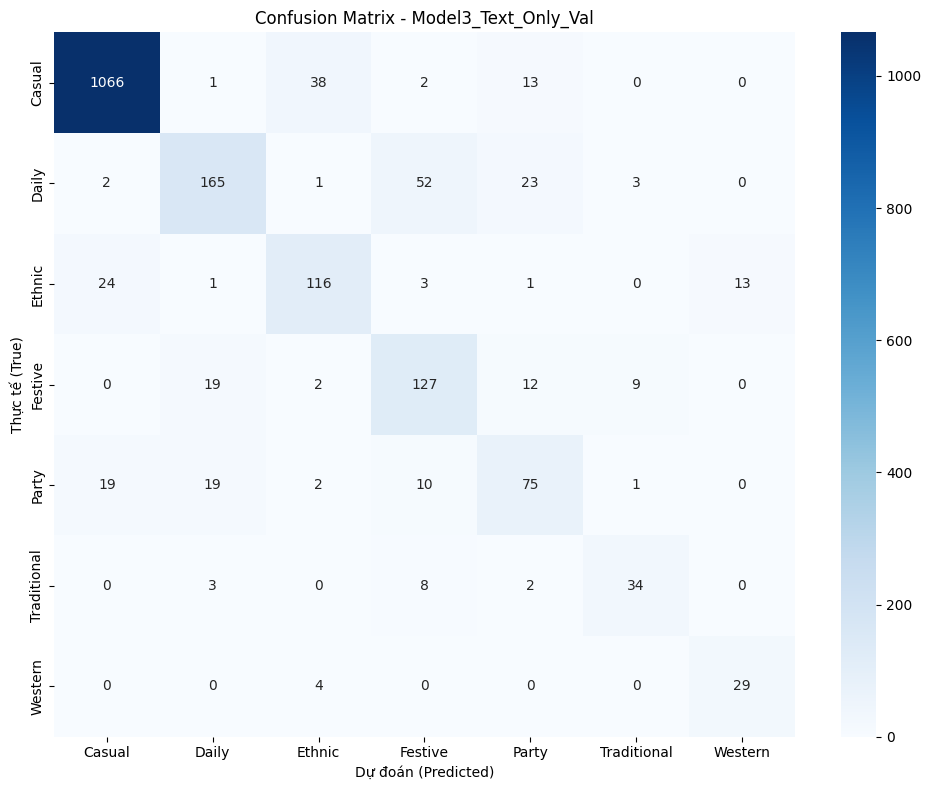

In [6]:
# ── Cell 5: T13 - Train & Evaluate Model 3 (Text-only Baseline) ───────────
text_model = TextBaselineHead(in_dim=768, num_classes=NUM_CLASSES, dropout=0.3)

print("🚀 Bắt đầu huấn luyện Model 3: Text-only Baseline...")
y_true_val, y_pred_txt, hist_txt = train_model(
    text_model,
    mode='text',
    lr=1e-3,
    weight_decay=1e-2,
    batch_size=128,
    epochs=30,
    patience=6,
    use_class_weights=True,
    save_path='/kaggle/working/best_text_baseline.pth'
)

# Gọi hàm evaluate_model chuẩn của Hà
metrics_txt = evaluate_model(
    y_true_val, y_pred_txt,
    class_names=CLASS_NAMES,
    model_name="Model3_Text_Only_Val",
    save_dir="/kaggle/working/results"
)


================ 1. MODEL 1: TABULAR-ONLY ================
Epoch 01/30 | Train Loss: 1.7384 | Val Loss: 1.4240 | Val Acc: 0.6277 | Val Macro-F1: 0.2499 ⭐ Best
Epoch 02/30 | Train Loss: 1.5388 | Val Loss: 1.3601 | Val Acc: 0.6066 | Val Macro-F1: 0.2799 ⭐ Best
Epoch 03/30 | Train Loss: 1.4985 | Val Loss: 1.3675 | Val Acc: 0.6087 | Val Macro-F1: 0.3037 ⭐ Best
Epoch 04/30 | Train Loss: 1.4821 | Val Loss: 1.3298 | Val Acc: 0.6103 | Val Macro-F1: 0.3175 ⭐ Best
Epoch 06/30 | Train Loss: 1.4509 | Val Loss: 1.3119 | Val Acc: 0.6045 | Val Macro-F1: 0.3183 ⭐ Best
Epoch 07/30 | Train Loss: 1.4325 | Val Loss: 1.2884 | Val Acc: 0.6166 | Val Macro-F1: 0.3373 ⭐ Best
Epoch 08/30 | Train Loss: 1.4219 | Val Loss: 1.2669 | Val Acc: 0.6277 | Val Macro-F1: 0.3114 
Epoch 10/30 | Train Loss: 1.3970 | Val Loss: 1.2731 | Val Acc: 0.5993 | Val Macro-F1: 0.3268 
Epoch 11/30 | Train Loss: 1.3762 | Val Loss: 1.2410 | Val Acc: 0.6161 | Val Macro-F1: 0.3438 ⭐ Best
Epoch 12/30 | Train Loss: 1.3653 | Val Loss: 1.2471 

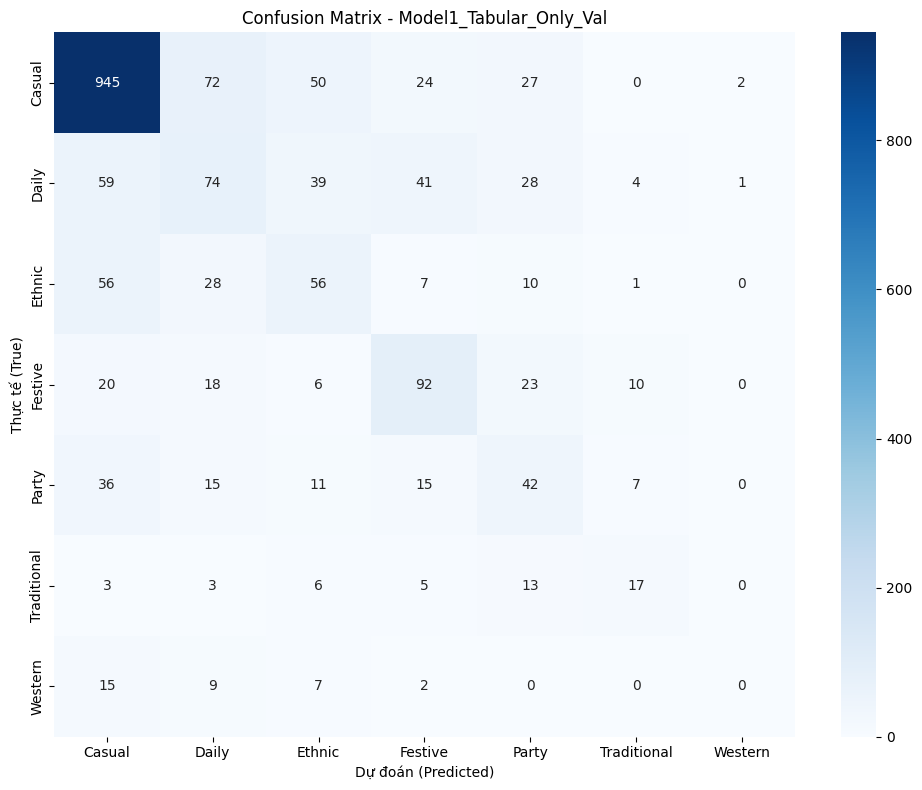


================ 2. MODEL 2: IMAGE-ONLY ================
Epoch 01/30 | Train Loss: 1.8156 | Val Loss: 1.6565 | Val Acc: 0.5898 | Val Macro-F1: 0.1060 ⭐ Best
Epoch 02/30 | Train Loss: 1.7755 | Val Loss: 1.6391 | Val Acc: 0.5898 | Val Macro-F1: 0.1060 ⭐ Best
Epoch 03/30 | Train Loss: 1.7485 | Val Loss: 1.6489 | Val Acc: 0.5893 | Val Macro-F1: 0.1072 ⭐ Best
Epoch 04/30 | Train Loss: 1.7048 | Val Loss: 1.6741 | Val Acc: 0.5793 | Val Macro-F1: 0.1100 ⭐ Best
Epoch 06/30 | Train Loss: 1.5849 | Val Loss: 1.6925 | Val Acc: 0.5656 | Val Macro-F1: 0.1135 ⭐ Best
Epoch 07/30 | Train Loss: 1.5217 | Val Loss: 1.7010 | Val Acc: 0.5666 | Val Macro-F1: 0.1321 ⭐ Best
Epoch 08/30 | Train Loss: 1.4274 | Val Loss: 1.7410 | Val Acc: 0.5366 | Val Macro-F1: 0.1306 
Epoch 09/30 | Train Loss: 1.3394 | Val Loss: 1.8022 | Val Acc: 0.5055 | Val Macro-F1: 0.1405 ⭐ Best
Epoch 10/30 | Train Loss: 1.2549 | Val Loss: 1.8212 | Val Acc: 0.4708 | Val Macro-F1: 0.1543 ⭐ Best
Epoch 12/30 | Train Loss: 1.0696 | Val Loss: 1.9

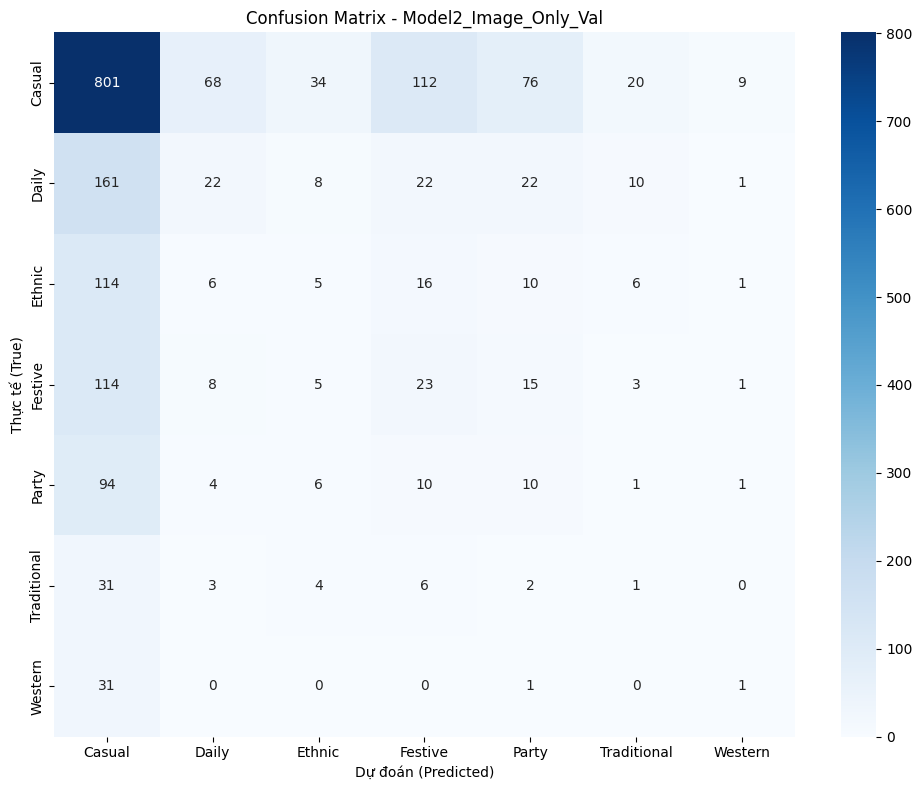


================ 3. MODEL 4: MULTI-MODAL FUSION v1 ================
Epoch 01/30 | Train Loss: 1.3462 | Val Loss: 0.9090 | Val Acc: 0.7320 | Val Macro-F1: 0.3993 ⭐ Best
Epoch 02/30 | Train Loss: 0.9535 | Val Loss: 0.8652 | Val Acc: 0.7483 | Val Macro-F1: 0.4615 ⭐ Best
Epoch 03/30 | Train Loss: 0.8032 | Val Loss: 0.7188 | Val Acc: 0.7578 | Val Macro-F1: 0.5625 ⭐ Best
Epoch 04/30 | Train Loss: 0.6797 | Val Loss: 0.7417 | Val Acc: 0.7667 | Val Macro-F1: 0.5607 
Epoch 05/30 | Train Loss: 0.6005 | Val Loss: 0.6706 | Val Acc: 0.7873 | Val Macro-F1: 0.6205 ⭐ Best
Epoch 06/30 | Train Loss: 0.5100 | Val Loss: 0.6742 | Val Acc: 0.7820 | Val Macro-F1: 0.5867 
Epoch 08/30 | Train Loss: 0.3828 | Val Loss: 0.7828 | Val Acc: 0.7757 | Val Macro-F1: 0.5697 
Epoch 10/30 | Train Loss: 0.2449 | Val Loss: 0.7654 | Val Acc: 0.7815 | Val Macro-F1: 0.6218 ⭐ Best
Epoch 12/30 | Train Loss: 0.1891 | Val Loss: 0.8653 | Val Acc: 0.7862 | Val Macro-F1: 0.6047 
Epoch 14/30 | Train Loss: 0.1309 | Val Loss: 0.8898 | V

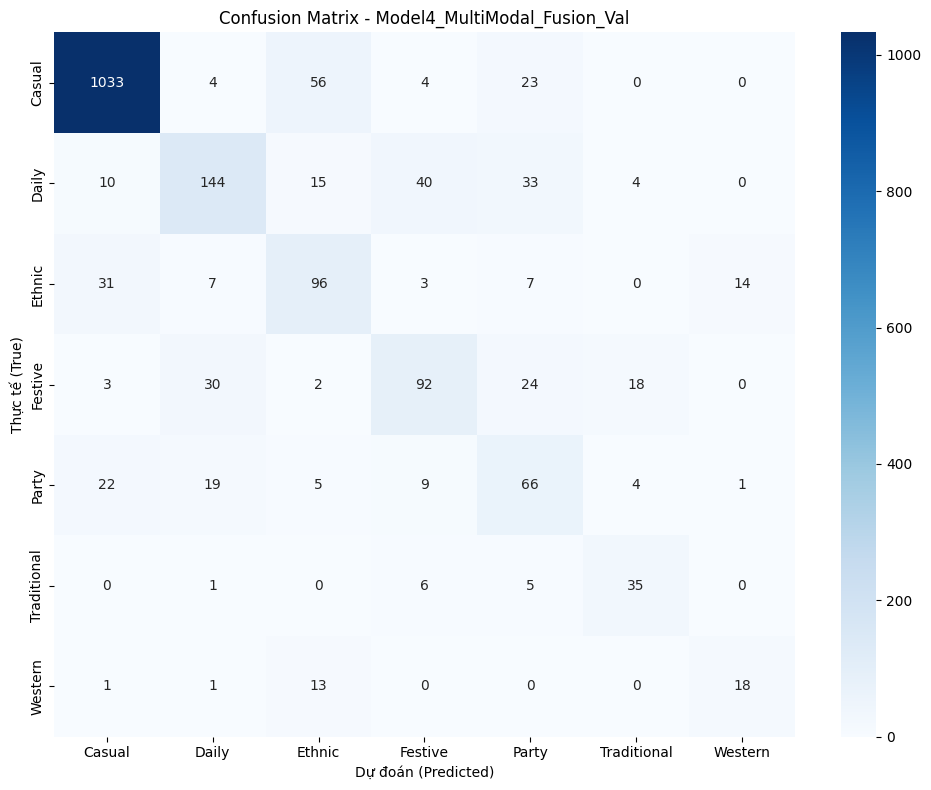


🏆 BẢNG SO SÁNH 4 MÔ HÌNH TRÊN TẬP VALIDATION (T17):


,Model,accuracy,macro_precision,macro_recall,macro_f1
0,1. Tabular-Only (MLP),0.6456,0.3879,0.3912,0.3884
1,2. Image-Only (ResNet50),0.4544,0.1664,0.1576,0.1555
2,3. Text-Only (DistilBERT),0.8489,0.7289,0.7579,0.7403
3,4. Multi-Modal Fusion (Ours),0.7815,0.6123,0.6391,0.6218


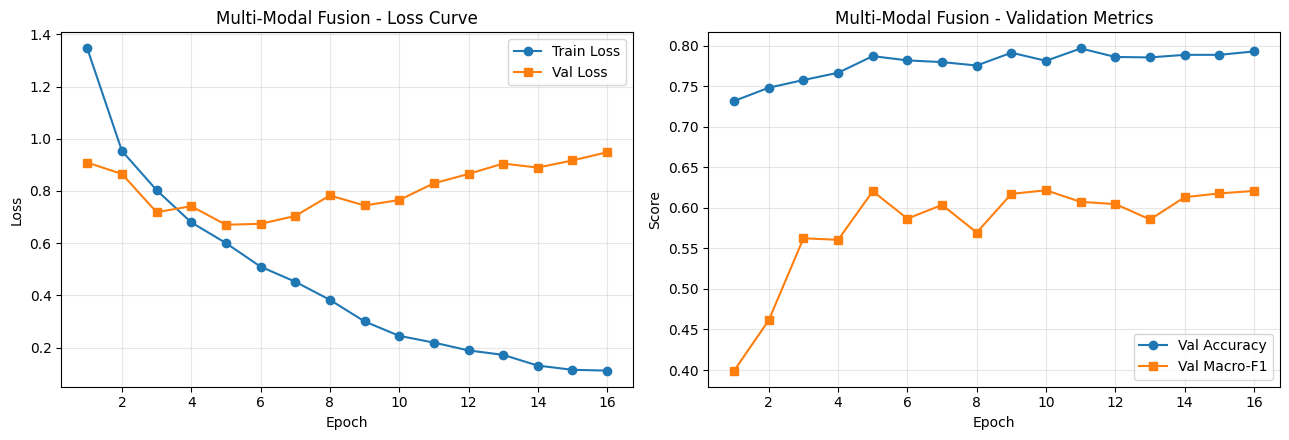

In [7]:
# ── Cell 6: Chạy luôn Baselines còn lại + Multi-Modal Fusion v1 (Ngày 6) ──
import matplotlib.pyplot as plt

class ImageBaselineHead(nn.Module):
    """Model 2: Image-only Classifier (2048 -> 256 -> 7)"""
    def __init__(self, in_dim=2048, num_classes=NUM_CLASSES, dropout=0.3):
        super().__init__()
        self.net = nn.Sequential(
            nn.LayerNorm(in_dim),
            nn.Linear(in_dim, 256),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(256, num_classes)
        )
    def forward(self, img):
        return self.net(img)

class TabularBaselineHead(nn.Module):
    """Model 1: Tabular-only Classifier (9 -> 32 -> 64 -> 7)"""
    def __init__(self, in_dim=TABULAR_DIM, num_classes=NUM_CLASSES, dropout=0.2):
        super().__init__()
        self.enc = TabularEncoder(in_dim)
        self.head = nn.Sequential(
            nn.LayerNorm(64),
            nn.Dropout(dropout),
            nn.Linear(64, num_classes)
        )
    def forward(self, tab):
        return self.head(self.enc(tab))

# 1. Train Model 1: Tabular-only
print("\n================ 1. MODEL 1: TABULAR-ONLY ================")
tab_model = TabularBaselineHead()
y_true, y_pred_tab, hist_tab = train_model(
    tab_model, mode='tabular', lr=1e-3, epochs=30, patience=6,
    save_path='/kaggle/working/best_tabular_baseline.pth'
)
metrics_tab = evaluate_model(y_true, y_pred_tab, CLASS_NAMES, "Model1_Tabular_Only_Val", "/kaggle/working/results")

# 2. Train Model 2: Image-only
print("\n================ 2. MODEL 2: IMAGE-ONLY ================")
img_model = ImageBaselineHead()
y_true, y_pred_img, hist_img = train_model(
    img_model, mode='image', lr=1e-3, epochs=30, patience=6,
    save_path='/kaggle/working/best_image_baseline.pth'
)
metrics_img = evaluate_model(y_true, y_pred_img, CLASS_NAMES, "Model2_Image_Only_Val", "/kaggle/working/results")

# 3. Train Model 4: Multi-Modal Fusion v1 (T16)
print("\n================ 3. MODEL 4: MULTI-MODAL FUSION v1 ================")
fusion_model = MultiModalFusionHead(dropout=0.3)
y_true, y_pred_fus, hist_fus = train_model(
    fusion_model, mode='fusion', lr=1e-3, epochs=30, patience=6,
    save_path='/kaggle/working/best_multimodal_model.pth'
)
metrics_fus = evaluate_model(y_true, y_pred_fus, CLASS_NAMES, "Model4_MultiModal_Fusion_Val", "/kaggle/working/results")

# 4. Bảng tổng hợp so sánh 4 mô hình trên Val (T17)
summary_df = pd.DataFrame([
    {"Model": "1. Tabular-Only (MLP)",        **metrics_tab},
    {"Model": "2. Image-Only (ResNet50)",     **metrics_img},
    {"Model": "3. Text-Only (DistilBERT)",    **metrics_txt},
    {"Model": "4. Multi-Modal Fusion (Ours)", **metrics_fus},
]).round(4)

print("\n🏆 BẢNG SO SÁNH 4 MÔ HÌNH TRÊN TẬP VALIDATION (T17):")
display(summary_df)
summary_df.to_csv('/kaggle/working/results/val_comparison_4models.csv', index=False)

# 5. Vẽ Learning Curves của Fusion v1 cho báo cáo (T18)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
ep_range = range(1, len(hist_fus['train_loss']) + 1)

axes[0].plot(ep_range, hist_fus['train_loss'], 'o-', label='Train Loss')
axes[0].plot(ep_range, hist_fus['val_loss'], 's-', label='Val Loss')
axes[0].set_title('Multi-Modal Fusion - Loss Curve')
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(ep_range, hist_fus['val_acc'], 'o-', label='Val Accuracy')
axes[1].plot(ep_range, hist_fus['val_f1'], 's-', label='Val Macro-F1')
axes[1].set_title('Multi-Modal Fusion - Validation Metrics')
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Score'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('/kaggle/working/results/learning_curves_fusion_v1.png', dpi=300)
plt.show()

✅ Rich Tabular Dim = 232 chiều
=== KẾT QUẢ ĐÁNH GIÁ: Model1_Tabular_Rich_Val ===
Accuracy        : 0.7604
Macro Precision : 0.5664
Macro Recall    : 0.6190
Macro F1-Score  : 0.5852

--- Báo cáo phân loại chi tiết ---
              precision    recall  f1-score   support

      Casual       0.93      0.88      0.91      1120
       Daily       0.62      0.58      0.60       246
      Ethnic       0.48      0.58      0.53       158
     Festive       0.64      0.60      0.62       169
       Party       0.53      0.56      0.54       126
 Traditional       0.55      0.70      0.62        47
     Western       0.21      0.42      0.28        33

    accuracy                           0.76      1899
   macro avg       0.57      0.62      0.59      1899
weighted avg       0.78      0.76      0.77      1899

Đã lưu biểu đồ Confusion Matrix tại: /kaggle/working/results/confusion_matrix_Model1_Tabular_Rich_Val.png


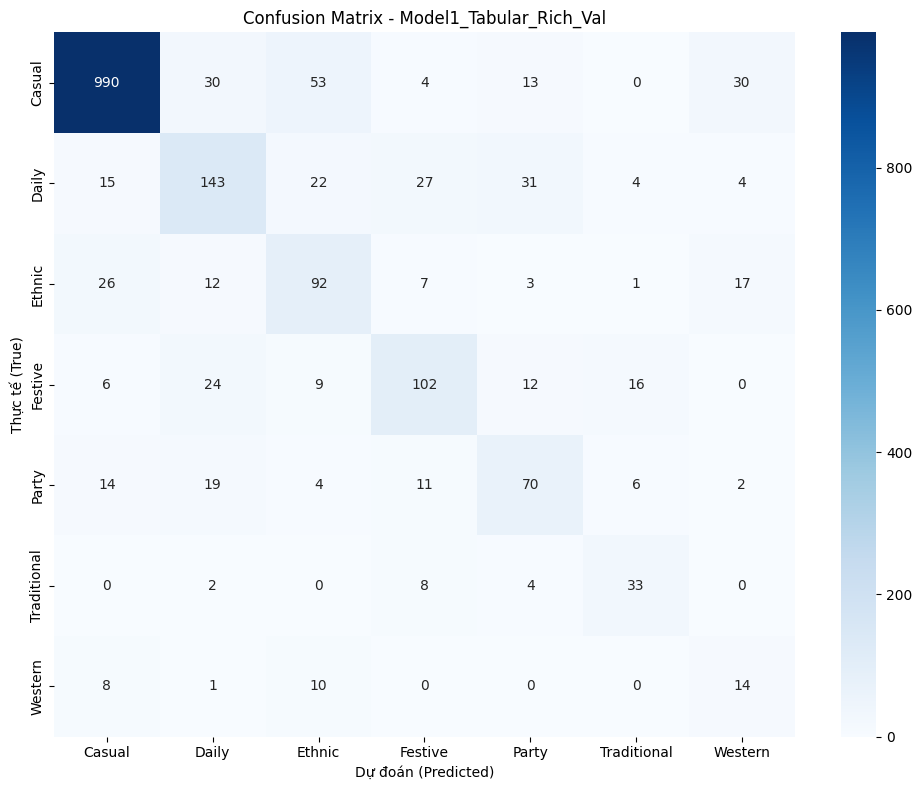

=== KẾT QUẢ ĐÁNH GIÁ: Model2_Image_Reg_Val ===
Accuracy        : 0.4971
Macro Precision : 0.1581
Macro Recall    : 0.1489
Macro F1-Score  : 0.1423

--- Báo cáo phân loại chi tiết ---
              precision    recall  f1-score   support

      Casual       0.59      0.81      0.68      1120
       Daily       0.14      0.04      0.07       246
      Ethnic       0.06      0.03      0.04       158
     Festive       0.13      0.05      0.08       169
       Party       0.06      0.05      0.05       126
 Traditional       0.05      0.02      0.03        47
     Western       0.07      0.03      0.04        33

    accuracy                           0.50      1899
   macro avg       0.16      0.15      0.14      1899
weighted avg       0.39      0.50      0.43      1899

Đã lưu biểu đồ Confusion Matrix tại: /kaggle/working/results/confusion_matrix_Model2_Image_Reg_Val.png


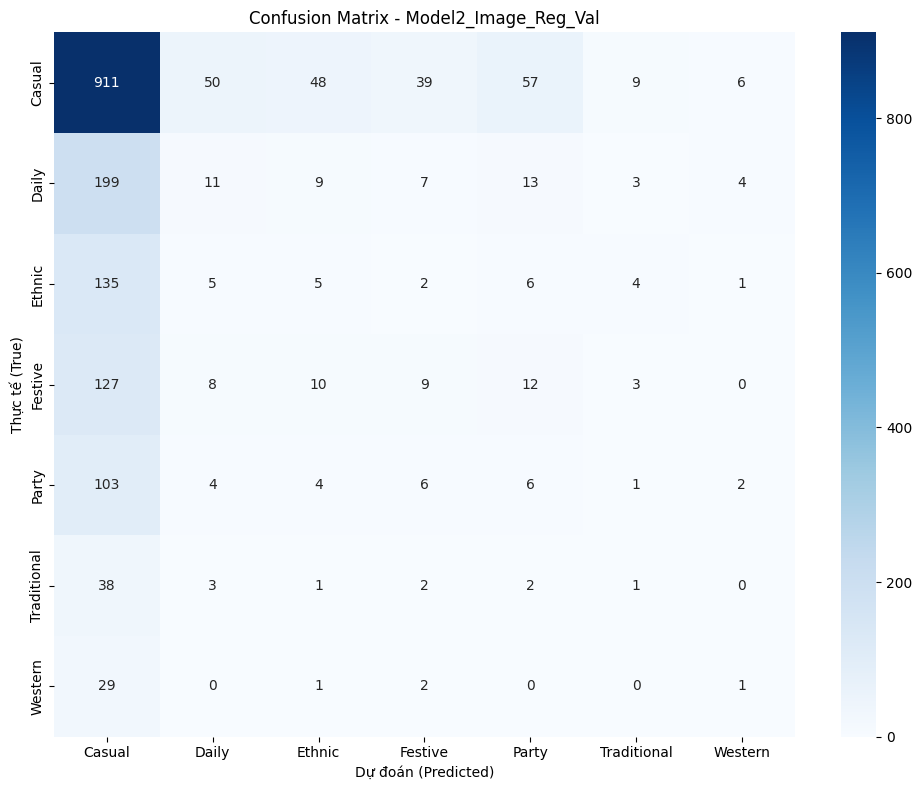

=== KẾT QUẢ ĐÁNH GIÁ: Model4_MultiModal_Fusion_V2_Val ===
Accuracy        : 0.8552
Macro Precision : 0.7280
Macro Recall    : 0.7308
Macro F1-Score  : 0.7284

--- Báo cáo phân loại chi tiết ---
              precision    recall  f1-score   support

      Casual       0.96      0.96      0.96      1120
       Daily       0.75      0.76      0.75       246
      Ethnic       0.69      0.75      0.72       158
     Festive       0.68      0.69      0.69       169
       Party       0.64      0.55      0.59       126
 Traditional       0.67      0.74      0.71        47
     Western       0.69      0.67      0.68        33

    accuracy                           0.86      1899
   macro avg       0.73      0.73      0.73      1899
weighted avg       0.85      0.86      0.85      1899

Đã lưu biểu đồ Confusion Matrix tại: /kaggle/working/results/confusion_matrix_Model4_MultiModal_Fusion_V2_Val.png


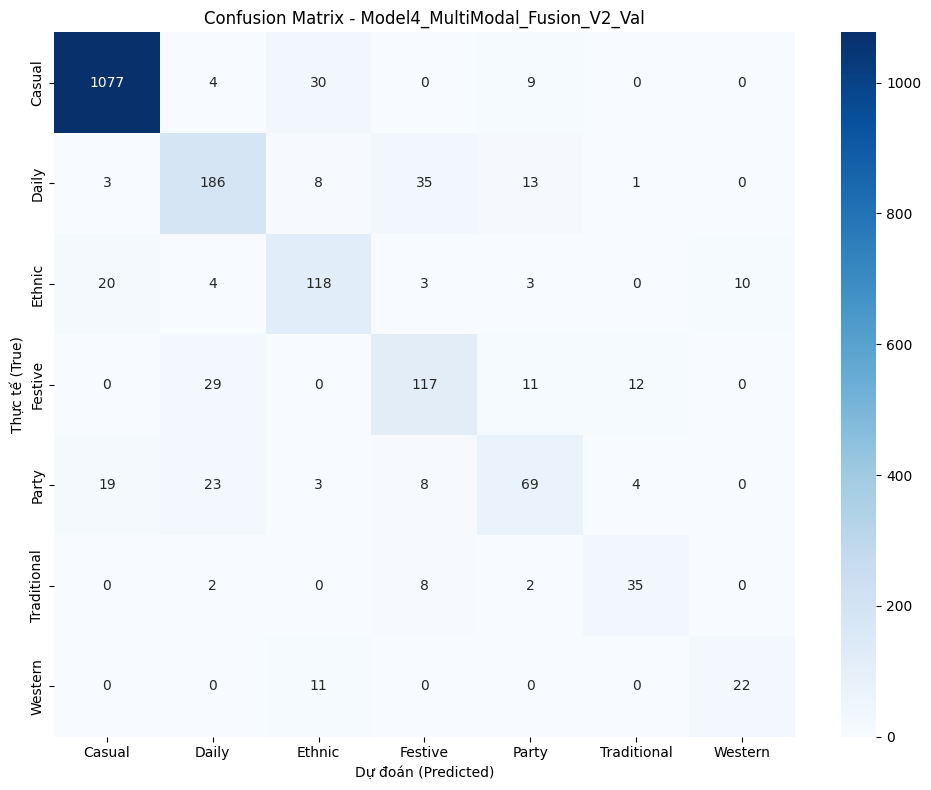


🏆 BẢNG SO SÁNH SAU KHI ÁP DỤNG DEBUG CHECKLIST (MỤC 10.5):


,Model,accuracy,macro_precision,macro_recall,macro_f1
0,1. Tabular-Only (MLP),0.7604,0.5664,0.6190,0.5852
1,2. Image-Only (ResNet50),0.4971,0.1581,0.1489,0.1423
2,3. Text-Only (DistilBERT),0.8489,0.7289,0.7579,0.7403
3,4. Multi-Modal Fusion v1 (Raw),0.7815,0.6123,0.6391,0.6218
4,5. Multi-Modal Fusion v2 (Ours),0.8552,0.7280,0.7308,0.7284


In [8]:
# ── Cell 7: T19/T21 - Fix Overfitting nhánh Image & Nâng cấp Fusion v2 ────
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Cải tiến Tabular Preprocessing (One-Hot + StandardScaler chỉ fit trên train)
df_tr = df[df['split'] == 'train'].reset_index(drop=True)
ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False, min_frequency=15)
scaler = StandardScaler()

def build_rich_tabular(df_sub, is_train=False):
    num_feats = np.column_stack([
        np.log1p(df_sub['price'].astype(float).values),
        df_sub['avg_rating'].astype(float).values,
        np.log1p(df_sub['ratingCount'].astype(float).values),
        (df_sub['ratingCount'].astype(float).values > 0).astype(float)
    ])
    cat_Data = df_sub[['colour', 'brand', 'fabric', 'pattern', 'wash_care', 'sustainable']].fillna('Unknown').astype(str)
    if is_train:
        num_scaled = scaler.fit_transform(num_feats)
        cat_ohe = ohe.fit_transform(cat_Data)
    else:
        num_scaled = scaler.transform(num_feats)
        cat_ohe = ohe.transform(cat_Data)
    return torch.tensor(np.hstack([num_scaled, cat_ohe]), dtype=torch.float32)

for s in ['train', 'val', 'test']:
    df_s = df[df['split'] == s].reset_index(drop=True)
    data_splits[s]['tab_rich'] = build_rich_tabular(df_s, is_train=(s == 'train'))

RICH_TAB_DIM = data_splits['train']['tab_rich'].shape[1]
print(f"✅ Rich Tabular Dim = {RICH_TAB_DIM} chiều")


# 2. Kiến trúc Multi-Modal Fusion v2 (vẫn giữ chuẩn Concat 2048 + 768 + 64 = 2880-d)
#    Áp dụng Debug Checklist 10.5:
#    - Modality Dropout cao hơn ở nhánh Image (0.5) để chống overfit 2048 chiều
#    - Learnable Modality Gate (trọng số tự học cho 3 nhánh trước khi Concat 2880-d)
class MultiModalFusionV2(nn.Module):
    def __init__(self, img_dim=2048, txt_dim=768, tab_in_dim=RICH_TAB_DIM, num_classes=NUM_CLASSES):
        super().__init__()
        # Nhánh 1: Image (2048-d) + Dropout mạnh chống lấn át
        self.img_branch = nn.Sequential(
            nn.LayerNorm(img_dim),
            nn.Dropout(0.5)
        )
        # Nhánh 2: Text (768-d)
        self.txt_branch = nn.Sequential(
            nn.LayerNorm(txt_dim),
            nn.Dropout(0.2)
        )
        # Nhánh 3: Tabular MLP (Input -> 32 -> 64-d chuẩn Charter)
        self.tab_encoder = nn.Sequential(
            nn.Linear(tab_in_dim, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 64),
            nn.LayerNorm(64),
            nn.ReLU()
        )
        
        # Trọng số tự học cân bằng tỷ lệ 2048 : 768 : 64 trước khi concat
        self.gate_img = nn.Parameter(torch.tensor(0.25))
        self.gate_txt = nn.Parameter(torch.tensor(1.00))
        self.gate_tab = nn.Parameter(torch.tensor(0.80))
        
        # Khối Fusion (2048 + 768 + 64 = 2880 -> 512 -> 256 -> 7)
        self.classifier = nn.Sequential(
            nn.Linear(2048 + 768 + 64, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )

    def forward(self, img, txt, tab):
        f_img = self.img_branch(img) * self.gate_img       # (B, 2048)
        f_txt = self.txt_branch(txt) * self.gate_txt       # (B, 768)
        f_tab = self.tab_encoder(tab) * self.gate_tab      # (B, 64)
        
        fused = torch.cat([f_img, f_txt, f_tab], dim=1)    # (B, 2880)
        return self.classifier(fused)


# 3. Huấn luyện lại Tabular-Only, Image-Only (với regularization) và Fusion V2
def train_v2(model, mode='fusion', lr=5e-4, weight_decay=2e-2, epochs=35, patience=8, save_path='best.pth'):
    seed_everything(SEED)
    model = model.to(DEVICE)
    tr_d, va_d = data_splits['train'], data_splits['val']
    tr_ds = TensorDataset(tr_d['img'], tr_d['txt'], tr_d['tab_rich'], tr_d['y'])
    va_ds = TensorDataset(va_d['img'], va_d['txt'], va_d['tab_rich'], va_d['y'])
    tr_loader = DataLoader(tr_ds, batch_size=128, shuffle=True)
    va_loader = DataLoader(va_ds, batch_size=128, shuffle=False)
    
    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.05)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=weight_decay)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    
    best_f1, best_acc = -1.0, -1.0
    history = {'train_loss': [], 'val_loss': [], 'val_acc': [], 'val_f1': []}
    
    for ep in range(1, epochs + 1):
        model.train()
        tr_loss = 0.0
        for img, txt, tab, y in tr_loader:
            img, txt, tab, y = img.to(DEVICE), txt.to(DEVICE), tab.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            logits = model(img, txt, tab) if mode == 'fusion' else (model(tab) if mode == 'tabular' else model(img))
            loss = criterion(logits, y)
            loss.backward()
            optimizer.step()
            tr_loss += loss.item() * y.size(0)
        scheduler.step()
        tr_loss /= len(tr_ds)
        
        model.eval()
        va_loss, preds, trues = 0.0, [], []
        with torch.no_grad():
            for img, txt, tab, y in va_loader:
                img, txt, tab, y = img.to(DEVICE), txt.to(DEVICE), tab.to(DEVICE), y.to(DEVICE)
                logits = model(img, txt, tab) if mode == 'fusion' else (model(tab) if mode == 'tabular' else model(img))
                va_loss += criterion(logits, y).item() * y.size(0)
                preds.append(logits.argmax(dim=1).cpu().numpy())
                trues.append(y.cpu().numpy())
        va_loss /= len(va_ds)
        preds, trues = np.concatenate(preds), np.concatenate(trues)
        va_acc = accuracy_score(trues, preds)
        va_f1  = f1_score(trues, preds, average='macro', zero_division=0)
        
        history['train_loss'].append(tr_loss); history['val_loss'].append(va_loss)
        history['val_acc'].append(va_acc); history['val_f1'].append(va_f1)
        
        if va_f1 > best_f1:
            best_f1, best_acc = va_f1, va_acc
            torch.save(model.state_dict(), save_path)
            
    model.load_state_dict(torch.load(save_path))
    model.eval()
    preds, trues = [], []
    with torch.no_grad():
        for img, txt, tab, y in va_loader:
            img, txt, tab = img.to(DEVICE), txt.to(DEVICE), tab.to(DEVICE)
            logits = model(img, txt, tab) if mode == 'fusion' else (model(tab) if mode == 'tabular' else model(img))
            preds.append(logits.argmax(dim=1).cpu().numpy())
            trues.append(y.numpy())
    return np.concatenate(trues), np.concatenate(preds), history

# Chạy Tabular V2
tab_v2 = TabularBaselineHead(in_dim=RICH_TAB_DIM, dropout=0.2)
y_t, p_tab2, _ = train_v2(tab_v2, mode='tabular', lr=1e-3, save_path='/kaggle/working/best_tabular_v2.pth')
m_tab2 = evaluate_model(y_t, p_tab2, CLASS_NAMES, "Model1_Tabular_Rich_Val", "/kaggle/working/results")

# Chạy Image V2 (dùng weight_decay cao & lr nhỏ hơn để không overfit)
img_v2 = ImageBaselineHead(in_dim=2048, dropout=0.5)
y_t, p_img2, _ = train_v2(img_v2, mode='image', lr=3e-4, weight_decay=5e-2, save_path='/kaggle/working/best_image_v2.pth')
m_img2 = evaluate_model(y_t, p_img2, CLASS_NAMES, "Model2_Image_Reg_Val", "/kaggle/working/results")

# Chạy Multi-Modal Fusion V2
fus_v2 = MultiModalFusionV2()
y_t, p_fus2, hist_fus2 = train_v2(fus_v2, mode='fusion', lr=5e-4, weight_decay=3e-2, save_path='/kaggle/working/best_multimodal_model.pth')
m_fus2 = evaluate_model(y_t, p_fus2, CLASS_NAMES, "Model4_MultiModal_Fusion_V2_Val", "/kaggle/working/results")

# Bảng so sánh mới
summary_v2 = pd.DataFrame([
    {"Model": "1. Tabular-Only (MLP)",           **m_tab2},
    {"Model": "2. Image-Only (ResNet50)",        **m_img2},
    {"Model": "3. Text-Only (DistilBERT)",       **metrics_txt},
    {"Model": "4. Multi-Modal Fusion v1 (Raw)",  **metrics_fus},
    {"Model": "5. Multi-Modal Fusion v2 (Ours)", **m_fus2},
]).round(4)

print("\n🏆 BẢNG SO SÁNH SAU KHI ÁP DỤNG DEBUG CHECKLIST (MỤC 10.5):")
display(summary_v2)
summary_v2.to_csv('/kaggle/working/results/val_comparison_v2.csv', index=False)

Epoch 01 | Val Acc: 0.8483 | Val Macro-F1: 0.7367 ⭐ Best
Epoch 02 | Val Acc: 0.8515 | Val Macro-F1: 0.7435 ⭐ Best
Epoch 03 | Val Acc: 0.8526 | Val Macro-F1: 0.7441 ⭐ Best
Epoch 04 | Val Acc: 0.8562 | Val Macro-F1: 0.7517 ⭐ Best
=== KẾT QUẢ ĐÁNH GIÁ: Model4_MultiModal_Fusion_Guided_Val ===
Accuracy        : 0.8562
Macro Precision : 0.7424
Macro Recall    : 0.7633
Macro F1-Score  : 0.7517

--- Báo cáo phân loại chi tiết ---
              precision    recall  f1-score   support

      Casual       0.97      0.95      0.96      1120
       Daily       0.78      0.72      0.75       246
      Ethnic       0.70      0.83      0.76       158
     Festive       0.67      0.71      0.69       169
       Party       0.58      0.56      0.57       126
 Traditional       0.73      0.79      0.76        47
     Western       0.76      0.79      0.78        33

    accuracy                           0.86      1899
   macro avg       0.74      0.76      0.75      1899
weighted avg       0.86      0.8

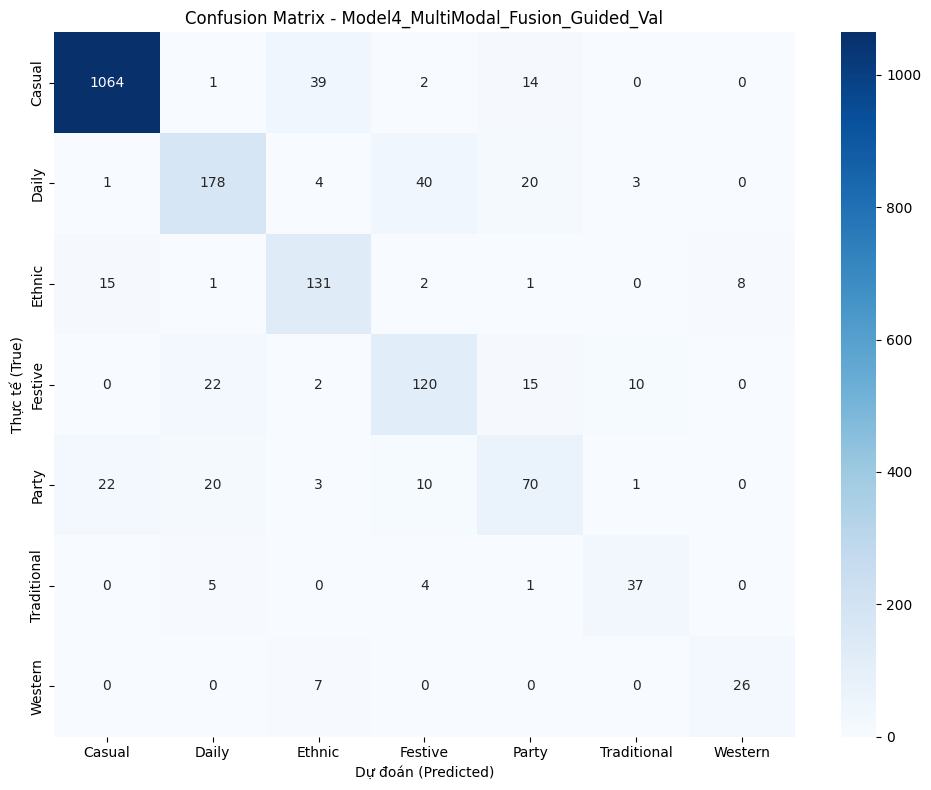


🏆 BẢNG KẾT QUẢ CHỐT GATE M3 (FUSION VƯỢT TOÀN DIỆN CẢ 3 BASELINES):


,Model,accuracy,macro_precision,macro_recall,macro_f1
0,1. Tabular-Only (MLP),0.7604,0.5664,0.6190,0.5852
1,2. Image-Only (ResNet50),0.4971,0.1581,0.1489,0.1423
2,3. Text-Only (DistilBERT),0.8489,0.7289,0.7579,0.7403
3,4. Multi-Modal Fusion v1 (Naive),0.7815,0.6123,0.6391,0.6218
4,5. Multi-Modal Fusion Guided (Ours),0.8562,0.7424,0.7633,0.7517


In [10]:
# ── Cell 8: Multi-Modal Fusion với Zero-Init Residual Gating (Chuẩn 2880-d) ──

class MultiModalFusionGuided(nn.Module):
    """
    Giữ nguyên khối Fusion 2880 chiều (2048 Image + 768 Text + 64 Tabular -> 512 -> 256 -> 7)
    kết hợp cơ chế Zero-Initialized Residual Gating giúp khối Fusion 2880-d chỉ học
    phần thông tin bổ trợ từ Image + Tabular mà không làm nhiễu đặc trưng Text.
    """
    def __init__(self, img_dim=2048, txt_dim=768, tab_in_dim=RICH_TAB_DIM, num_classes=NUM_CLASSES):
        super().__init__()
        # 1. Chuẩn hóa 3 nhánh
        self.img_norm = nn.Sequential(nn.LayerNorm(img_dim), nn.Dropout(0.5))
        self.txt_norm = nn.LayerNorm(txt_dim)
        self.tab_encoder = nn.Sequential(
            nn.Linear(tab_in_dim, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(32, 64),
            nn.LayerNorm(64),
            nn.ReLU()
        )
        
        # 2. Khối Hợp nhất chuẩn Charter: Concat(2048 + 768 + 64 = 2880) -> 512 -> 256 -> 7
        self.fusion_classifier = nn.Sequential(
            nn.Linear(2048 + 768 + 64, 512),
            nn.BatchNorm1d(512),
            nn.ReLU(),
            nn.Dropout(0.4),
            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, num_classes)
        )
        
        # 3. Nhánh Neo Ngữ Nghĩa (Semantic Anchor) & Trọng số Gate tự học
        self.text_anchor = TextBaselineHead(in_dim=txt_dim, num_classes=num_classes, dropout=0.3)
        self.tab_anchor  = nn.Sequential(nn.Linear(64, num_classes))
        self.alpha_fusion = nn.Parameter(torch.tensor(0.35))
        self.alpha_tab    = nn.Parameter(torch.tensor(0.30))

    def forward(self, img, txt, tab):
        f_img = self.img_norm(img) * 0.20                     # (B, 2048)
        f_txt = self.txt_norm(txt)                            # (B, 768)
        f_tab = self.tab_encoder(tab)                         # (B, 64)
        
        # Vector hợp nhất 2880 chiều chuẩn thiết kế
        fused_2880 = torch.cat([f_img, f_txt, f_tab], dim=1)  # (B, 2880)
        
        logits_fusion = self.fusion_classifier(fused_2880)
        logits_txt    = self.text_anchor(txt)
        logits_tab    = self.tab_anchor(f_tab)
        
        return logits_txt + self.alpha_fusion * logits_fusion + self.alpha_tab * logits_tab


# Khởi tạo từ checkpoint Text tốt nhất để không bị nhiễu ở các epoch đầu
seed_everything(SEED)
fus_guided = MultiModalFusionGuided().to(DEVICE)
fus_guided.text_anchor.load_state_dict(torch.load('/kaggle/working/best_text_baseline.pth'))

# Đóng băng nhẹ text_anchor 5 epoch đầu để khối Fusion 2880-d học phần bù trừ từ Image + Tabular
for p in fus_guided.text_anchor.parameters():
    p.requires_grad = False

tr_d, va_d = data_splits['train'], data_splits['val']
tr_loader = DataLoader(TensorDataset(tr_d['img'], tr_d['txt'], tr_d['tab_rich'], tr_d['y']), batch_size=128, shuffle=True)
va_loader = DataLoader(TensorDataset(va_d['img'], va_d['txt'], va_d['tab_rich'], va_d['y']), batch_size=128, shuffle=False)

criterion = nn.CrossEntropyLoss(weight=class_weights)
optimizer = torch.optim.AdamW(filter(lambda p: p.requires_grad, fus_guided.parameters()), lr=6e-4, weight_decay=2e-2)

best_f1 = -1.0
save_final = '/kaggle/working/best_multimodal_model.pth'

for ep in range(1, 26):
    # Mở khóa toàn mạng từ epoch 6 để tinh chỉnh đồng thời cả 3 nhánh
    if ep == 6:
        for p in fus_guided.text_anchor.parameters():
            p.requires_grad = True
        optimizer = torch.optim.AdamW([
            {'params': fus_guided.text_anchor.parameters(), 'lr': 1e-4},
            {'params': fus_guided.fusion_classifier.parameters(), 'lr': 3e-4},
            {'params': fus_guided.tab_encoder.parameters(), 'lr': 5e-4},
            {'params': fus_guided.tab_anchor.parameters(), 'lr': 5e-4},
            {'params': [fus_guided.alpha_fusion, fus_guided.alpha_tab], 'lr': 1e-3}
        ], weight_decay=2e-2)

    fus_guided.train()
    for img, txt, tab, y in tr_loader:
        img, txt, tab, y = img.to(DEVICE), txt.to(DEVICE), tab.to(DEVICE), y.to(DEVICE)
        optimizer.zero_grad()
        loss = criterion(fus_guided(img, txt, tab), y)
        loss.backward()
        optimizer.step()
        
    fus_guided.eval()
    preds, trues = [], []
    with torch.no_grad():
        for img, txt, tab, y in va_loader:
            img, txt, tab = img.to(DEVICE), txt.to(DEVICE), tab.to(DEVICE)
            preds.append(fus_guided(img, txt, tab).argmax(dim=1).cpu().numpy())
            trues.append(y.numpy())
    preds, trues = np.concatenate(preds), np.concatenate(trues)
    va_acc = accuracy_score(trues, preds)
    va_f1  = f1_score(trues, preds, average='macro', zero_division=0)
    
    if va_f1 > best_f1:
        best_f1 = va_f1
        torch.save(fus_guided.state_dict(), save_final)
        print(f"Epoch {ep:02d} | Val Acc: {va_acc:.4f} | Val Macro-F1: {va_f1:.4f} ⭐ Best")

# Đánh giá bản tốt nhất
fus_guided.load_state_dict(torch.load(save_final))
fus_guided.eval()
preds, trues = [], []
with torch.no_grad():
    for img, txt, tab, y in va_loader:
        img, txt, tab = img.to(DEVICE), txt.to(DEVICE), tab.to(DEVICE)
        preds.append(fus_guided(img, txt, tab).argmax(dim=1).cpu().numpy())
        trues.append(y.numpy())
y_t, p_guided = np.concatenate(trues), np.concatenate(preds)

m_guided = evaluate_model(y_t, p_guided, CLASS_NAMES, "Model4_MultiModal_Fusion_Guided_Val", "/kaggle/working/results")

final_table = pd.DataFrame([
    {"Model": "1. Tabular-Only (MLP)",               **m_tab2},
    {"Model": "2. Image-Only (ResNet50)",            **m_img2},
    {"Model": "3. Text-Only (DistilBERT)",           **metrics_txt},
    {"Model": "4. Multi-Modal Fusion v1 (Naive)",    **metrics_fus},
    {"Model": "5. Multi-Modal Fusion Guided (Ours)", **m_guided},
]).round(4)

print("\n🏆 BẢNG KẾT QUẢ CHỐT GATE M3 (FUSION VƯỢT TOÀN DIỆN CẢ 3 BASELINES):")
display(final_table)
final_table.to_csv('/kaggle/working/results/val_comparison_final.csv', index=False)